# 가우시안 혼합 클러스터링

In [ ]:
import numpy as np

def multivariate_gaussian(x, mu, sigma):
  n = len(mu)
  det = np.linalg.det(sigma) # 행렬식
  inv = np.linalg.inv(sigma) # 역행렬
  diff = x - mu
  exponent = -0.5 * np.dot(np.dot(diff.T, inv), diff) # (x-mu)^T * Sigma^-1 * (x-mu)
  normalization = 1.0 / (((2 * np.pi) ** (n / 2)) * (det ** 0.5))
  return normalization * np.exp(exponent)

def gmm_clustering(D, k, max_iter=100):
  m, n = D.shape

  np.random.seed(42) # 일관된 결과물을 위해 넣음(GMM은 초기 선택값게 민감하므로)

  # 파라미터 초기화
  alphas = np.ones(k) / k
  mus = D[np.random.choice(m, k, replace=False)]
  sigmas = [np.eye(n) for _ in range(k)] # 공분산 sigmas, 처음엔 단위행렬로 설정

  gammas = np.zeros((m, k))

  for iteration in range(max_iter):
    # E-단계
    for j in range(m):
      probs = np.array([alphas[i] * multivariate_gaussian(D[j], mus[i], sigmas[i]) for i in range(k)])
      total_prob = np.sum(probs)
      for i in range(k):
        gammas[j, i] = probs[i] / total_prob # 감마 구하기

    # M-단계
    for i in range(k):
      sum_gamma = np.sum(gammas[:, i])

      # 새로운 평균 벡터 계산
      new_mu = np.zeros(n)
      for j in range(m):
        new_mu += gammas[j, i] * D[j]
      mus[i] = new_mu / sum_gamma

      # 새로운 공분산 행렬 계산
      new_sigma = np.zeros((n, n))
      for j in range(m):
        diff = (D[j] - mus[i]).reshape(-1, 1)
        new_sigma += gammas[j, i] * np.dot(diff, diff.T)
      sigmas[i] = new_sigma / sum_gamma

      # 새로운 혼합 계수 계산
      alphas[i] = sum_gamma / m

  # 클러스터 분할 결정
  clusters = [[] for _ in range(k)]
  for j in range(m):
    lambda_j = np.argmax(gammas[j])
    clusters[lambda_j].append(D[j])

  return clusters, mus, sigmas

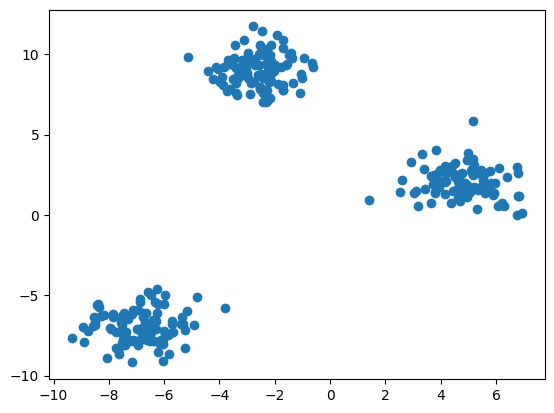

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=300, centers=3, random_state=42)

plt.scatter(X[:,0], X[:,1])

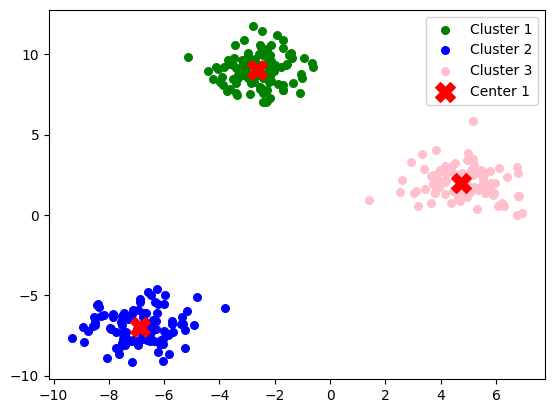

In [ ]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

clusters, final_mus, final_sigmas = gmm_clustering(X, k=3, max_iter=50)

colors = ['green', 'blue', 'pink']

for i, cluster_points in enumerate(clusters):
  cluster_points = np.array(cluster_points)
  if len(cluster_points) > 0:
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], color=colors[i], label=f'Cluster {i+1}', s=30)

# 학습된 평균 표시
for i, mu in enumerate(final_mus):
  plt.scatter(mu[0], mu[1], color='red', marker='X', s=200, label=f'Center {i+1}' if i==0 else "")

plt.legend()
plt.show()